# L2 of the assigned fish over all 71 recordings, Denis' analytic model (no ground truth)

**Model run.** Denis' analytic pipeline with my mask midline on all 71 Kaden recordings of 2024-02-20 (run of 2026-11-05/06,
re-synchronised EOD tables, no frame offset): per EOD his recorded peak-to-peak pattern `recorded_ptp` (10 pairs, V, signed) and his
prediction for every fish `predicted_ptp` (his units), `<t>/denis_predicted_voltages.npz`; his shape L2 per fish (each pattern
scaled to max |v| = 1) and his pick, `<t>/denis_assignments.csv`.

**Shape rule**: the fish with the smallest shape L2 (Denis' own pick, `fish | Denis, L2 (max |v| = 1)`).

**Voltage rule**: predicted voltage of fish f on pair p = $a_f\, e_k\, \text{pred}_{f,p}$, with $k$ the electrode of pair p (+ or −)
nearer to f's mask midline in that frame (original electrode positions, the ones his model uses); the fish with the smallest
$\lVert r - \hat r_f\rVert$ (volts) gets the EOD. **Factors** from the clean set `best100_per_fish_per_recording_71.csv` (per
recording and fish the 100 lowest shape-L2 EODs that pass: good masks for all fish, emitter ≥ 10 cm from the others, lowest shape L2,
its 2 nearest pairs = the 2 loudest recorded pairs with the model's sign, other fish ≤ ½ its predicted |v| there; fewer than 100
where not enough pass): on each EOD's 2 loudest recorded pairs $g = |r_p| / |\text{pred}_{f,p}|$ for the emitter (left out: wrong
sign or |pred| < 5% of its max); fish factor $a_f$ = median of its ratios; electrode factor $e_k$ = median of $g / a_f$ at electrode
k (1 where no ratios).

**Histograms**: for the EODs with a pick, the L2 of the assigned fish: shape L2 (shape rule), voltage L2 / max|r| and voltage L2 in
V (voltage rule), per assigned fish and pooled; all EODs (grey) and EODs whose frame passes the mask QC (outline). Log-spaced bins,
each group normalised to its own total; n in every legend.

In [1]:
import os, glob, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

BASE, LET, P = 'results/eod_assign_4fish_kaden', 'ABCD', 912
OUT = f'{BASE}/l2_distributions/denis_71'; os.makedirs(OUT, exist_ok=True)
FISH_COL = {'A': '#1F5FBF', 'B': '#17A0B0', 'C': '#F08A24', 'D': '#C8361E', 'all': '#2b2b2b'}
ORDER = [f'{p}{s}' for p in range(1, 11) for s in ('+', '−')]
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#e6e6e3',
                     'axes.axisbelow': True, 'axes.edgecolor': '#8a8a85', 'axes.labelcolor': '#2b2b2b',
                     'xtick.color': '#5a5a55', 'ytick.color': '#5a5a55'})
EL = pd.read_csv('data/electrodes/electrodes_signed_px_coord_4-fish.csv').sort_values('pair')
PLUS = np.array([(r.x1, r.y1) if str(r.pol1).strip() == '+' else (r.x2, r.y2) for _, r in EL.iterrows()], float)
MINUS = np.array([(r.x2, r.y2) if str(r.pol1).strip() == '+' else (r.x1, r.y1) for _, r in EL.iterrows()], float)
RECS = sorted(os.path.basename(os.path.dirname(p)) for p in glob.glob(f'{BASE}/*/denis_predicted_voltages.npz'))

def nearer_pole(mids, chunk=1500):
    '''(n, 4, 10): 0 = + pole of the pair nearer to the fish's midline, 1 = - pole (0 where no midline).'''
    out = np.zeros(mids.shape[:2] + (10,), np.int8)
    for s in range(0, len(mids), chunk):
        xy = mids[s:s + chunk, :, :, ::-1] * (P - 1)
        dp = np.linalg.norm(xy[:, :, :, None] - PLUS[None, None, None], axis=-1).min(2)
        dm = np.linalg.norm(xy[:, :, :, None] - MINUS[None, None, None], axis=-1).min(2)
        out[s:s + chunk] = (dm < dp)
    return out

# --- factors from the 100-best clean set
S = pd.read_csv(f'{BASE}/clean_emitter_set_71/best100_per_fish_per_recording_71.csv')
rat = []
for t, g in S.groupby('video'):
    z = np.load(f'{BASE}/{t}/denis_predicted_voltages.npz', allow_pickle=True); R, M = z['recorded_ptp'], z['predicted_ptp']
    mz = np.load(f'{BASE}/{t}/midlines_by_frame.npz'); gi = {int(k): i for i, k in enumerate(mz['frames'])}; mids = mz['mids']
    for r in g.itertuples():
        j = LET.index(r.fish); rec, pr = R[r.row], M[r.row, j]
        pole = nearer_pole(mids[[gi[int(r.Frame)]]])[0, j]
        for p in np.argsort(-np.abs(rec))[:2]:
            if np.sign(rec[p]) == np.sign(pr[p]) and abs(pr[p]) >= 0.05 * np.abs(pr).max():
                rat.append(dict(video=t, row=r.row, fish=r.fish, pair=p + 1, electrode=f'{p + 1}{"+−"[pole[p]]}', gain=abs(rec[p]) / abs(pr[p])))
RT = pd.DataFrame(rat); RT.to_csv(f'{OUT}/factor_ratios_best100.csv', index=False)
A_F = RT.groupby('fish').gain.median()
RT['g_over_a'] = RT.gain / RT.fish.map(A_F)
E_K = RT.groupby('electrode').g_over_a.median().reindex(ORDER).fillna(1.0)
FAC = pd.DataFrame({'factor': [f'fish {f}' for f in LET] + [f'electrode {e}' for e in ORDER],
                    'value': list(A_F.reindex(list(LET))) + list(E_K), 'n_ratios': list(RT.fish.value_counts().reindex(list(LET))) +
                    list(RT.electrode.value_counts().reindex(ORDER).fillna(0).astype(int))})
FAC.to_csv(f'{OUT}/denis_voltage_rule_factors_median.csv', index=False)
print(f'{len(RT)} ratios from {RT[["video", "row"]].drop_duplicates().shape[0]} EODs'); display(FAC.set_index('factor').T.round(4))
A = A_F.reindex(list(LET)).to_numpy(); E = E_K.to_numpy().reshape(10, 2)

36449 ratios from 18233 EODs


factor,fish A,fish B,fish C,fish D,electrode 1+,electrode 1−,electrode 2+,electrode 2−,electrode 3+,electrode 3−,...,electrode 6+,electrode 6−,electrode 7+,electrode 7−,electrode 8+,electrode 8−,electrode 9+,electrode 9−,electrode 10+,electrode 10−
value,0.0078,0.0046,0.0071,0.0043,1.0753,0.8821,0.6879,1.0619,0.926,0.5767,...,1.1357,0.9884,1.0018,1.0639,0.9402,0.9509,0.8272,0.812,0.5551,1.1497
n_ratios,9108.0000,11461.0000,10792.0000,5088.0000,1004.0000,2327.0000,1453.0000,1004.0000,797.000,1365.0000,...,4137.0000,2084.0000,1362.0000,2858.0000,1493.0000,1299.0000,1651.0000,782.000,2207.0000,6872.0000


In [2]:
# --- voltage rule and L2 on every EOD of the 71 recordings
t0 = time.time(); parts = []
for t in RECS:
    z = np.load(f'{BASE}/{t}/denis_predicted_voltages.npz', allow_pickle=True); R, M, fr = z['recorded_ptp'], z['predicted_ptp'], z['frame']
    den = pd.read_csv(f'{BASE}/{t}/denis_assignments.csv', usecols=['fish | Denis, L2 (max |v| = 1)'] + [f'L2 {f} (max |v| = 1)' for f in LET])
    mz = np.load(f'{BASE}/{t}/midlines_by_frame.npz'); gi = {int(k): i for i, k in enumerate(mz['frames'])}
    pole_f = nearer_pole(mz['mids']); idx = np.array([gi.get(int(k), -1) for k in fr])
    pole = np.where(idx[:, None, None] >= 0, pole_f[np.clip(idx, 0, None)], 0)
    pred = A[None, :, None] * E[np.arange(10)[None, None, :], pole] * M
    dv = np.linalg.norm(R[:, None] - pred, axis=2)
    ok = np.isfinite(dv).any(1)
    pv = np.where(ok, np.nanargmin(np.where(np.isfinite(dv), dv, np.inf), 1), -1)
    ii = np.arange(len(R)); rmax = np.abs(R).max(1)
    ps = den['fish | Denis, L2 (max |v| = 1)'].fillna('').to_numpy(); L2s = den[[f'L2 {f} (max |v| = 1)' for f in LET]].to_numpy()
    psi = np.array([LET.index(x) if x else -1 for x in ps])
    good = np.isin(fr, pd.read_csv(f'{BASE}/{t}/mask_qc_good_frames.csv').frame.to_numpy())
    parts.append(pd.DataFrame({'video': t, 'row': ii, 'Frame': fr, 'good': good, 'r_max': rmax,
                               'pick_shape': ps, 'l2_shape': np.where(psi >= 0, L2s[ii, np.clip(psi, 0, None)], np.nan),
                               'pick_voltage': np.where(pv >= 0, np.array(list(LET))[np.clip(pv, 0, None)], ''),
                               'l2_volt': np.where(pv >= 0, dv[ii, np.clip(pv, 0, None)], np.nan)}))
    del mz, pole_f, pole
DL = pd.concat(parts, ignore_index=True); DL['l2_rel'] = DL.l2_volt / DL.r_max
DL.to_csv(f'{OUT}/denis_71_l2_per_eod.csv.gz', index=False)
print(f'{len(DL)} EODs in {DL.video.nunique()} recordings, {(time.time() - t0) / 60:.1f} min; with a shape pick {(DL.pick_shape != "").sum()}, '
      f'with a voltage pick {(DL.pick_voltage != "").sum()}; good masks {DL.good.mean() * 100:.1f}%')
both = (DL.pick_shape != '') & (DL.pick_voltage != '')
print(f'voltage rule agrees with the shape rule on {(DL.pick_shape == DL.pick_voltage)[both].mean() * 100:.1f}% (good masks '
      f'{(DL.pick_shape == DL.pick_voltage)[both & DL.good].mean() * 100:.1f}%)')
display(pd.DataFrame({'shape rule': DL[DL.pick_shape != ''].pick_shape.value_counts(normalize=True).reindex(list(LET)) * 100,
                      'voltage rule': DL[DL.pick_voltage != ''].pick_voltage.value_counts(normalize=True).reindex(list(LET)) * 100}).round(1).T)

3667494 EODs in 71 recordings, 12.0 min; with a shape pick 3498433, with a voltage pick 3498433; good masks 33.5%


voltage rule agrees with the shape rule on 96.9% (good masks 98.4%)


,A,B,C,D
shape rule,29.5,17.5,27.5,25.5
voltage rule,29.1,17.2,27.4,26.3


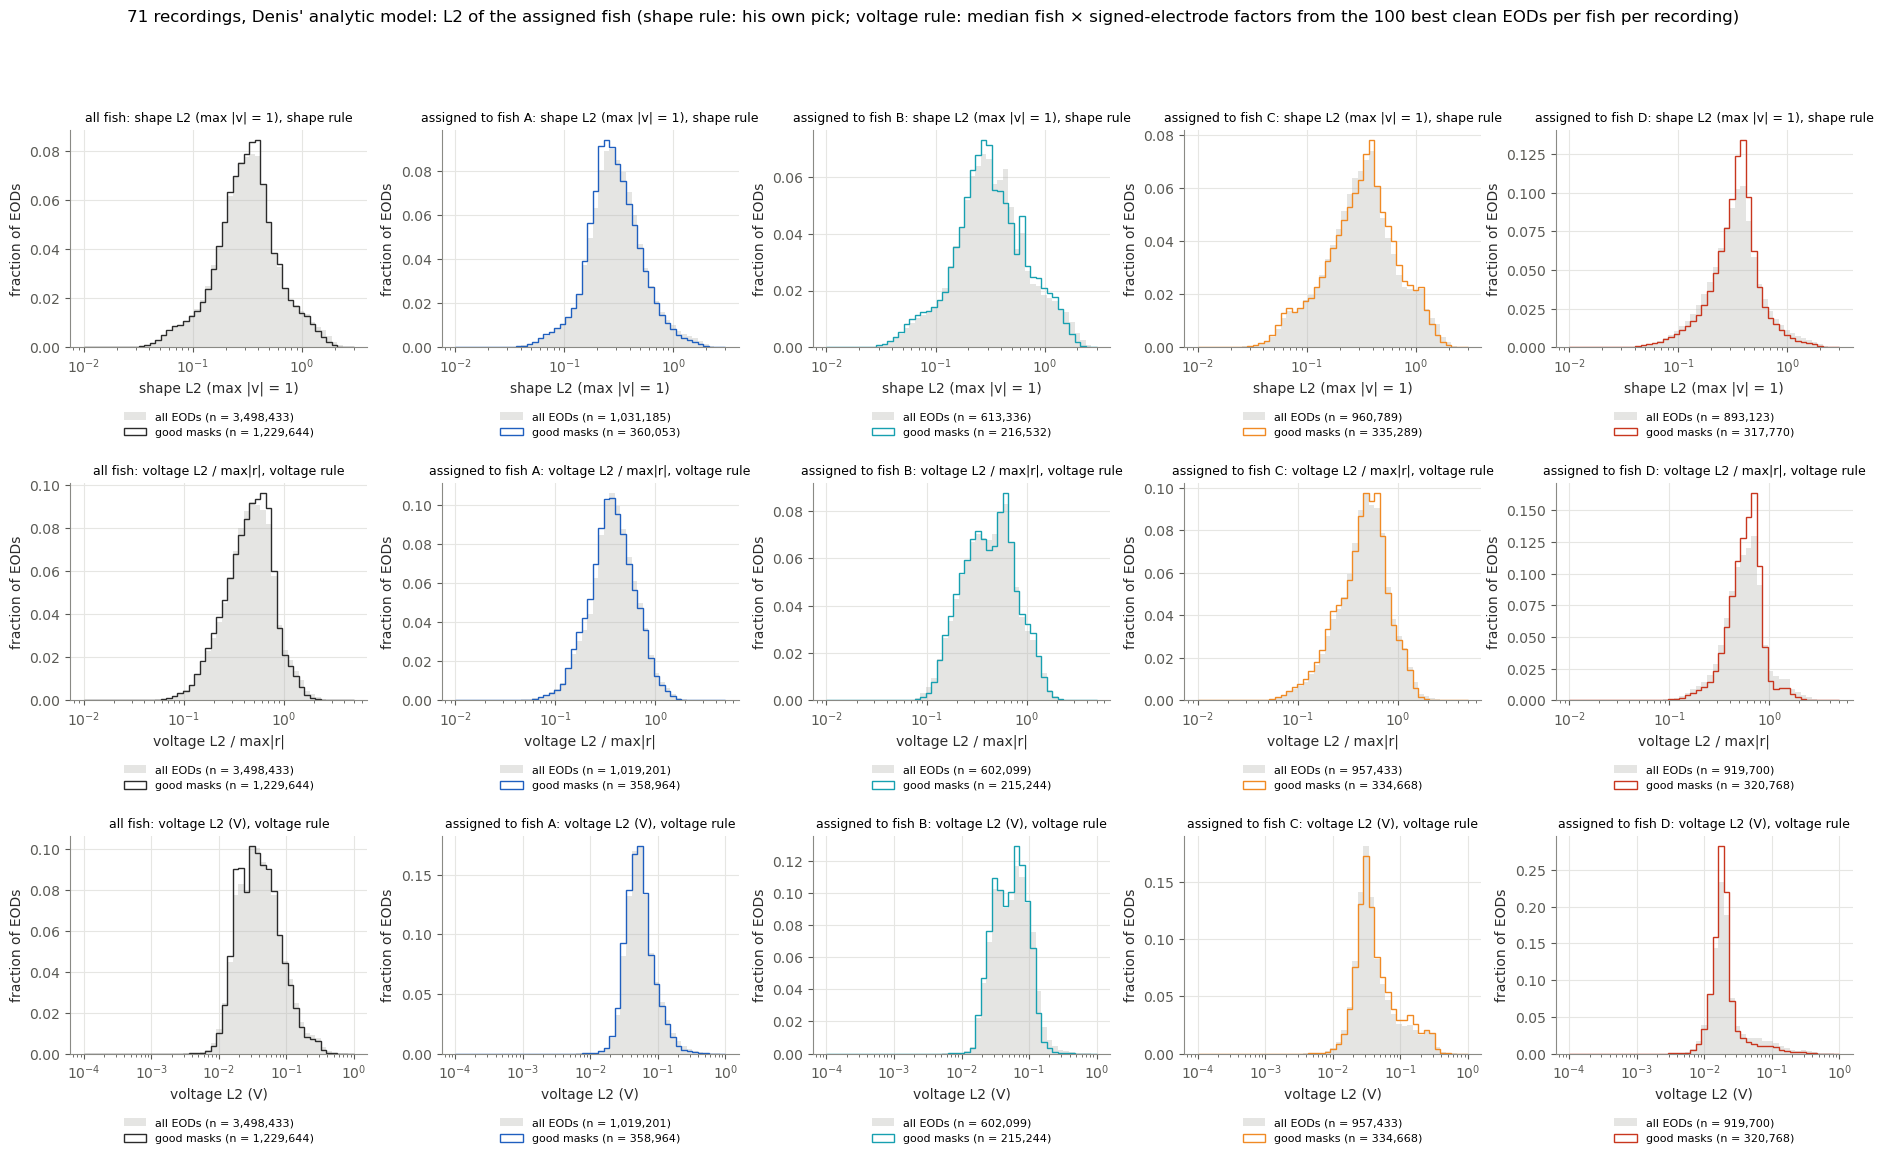

,measure,fish,n,n_good,median,p90,median_good,share_above_1
0,"shape L2 (max |v| = 1), shape rule",all,3498433,1229644,0.3139,0.7405,0.3144,5.4301
1,"shape L2 (max |v| = 1), shape rule",A,1031185,360053,0.2897,0.6251,0.2771,3.2448
2,"shape L2 (max |v| = 1), shape rule",B,613336,216532,0.3108,0.9122,0.3009,8.4795
3,"shape L2 (max |v| = 1), shape rule",C,960789,335289,0.3210,0.8646,0.3311,7.2160
4,"shape L2 (max |v| = 1), shape rule",D,893123,317770,0.3374,0.6658,0.3480,3.9378
5,"voltage L2 / max|r|, voltage rule",all,3498433,1229644,0.4628,0.8775,0.4642,6.8773
6,"voltage L2 / max|r|, voltage rule",A,1019201,358964,0.3803,0.7378,0.3674,3.0824
7,"voltage L2 / max|r|, voltage rule",B,602099,215244,0.4280,0.9342,0.4274,8.3003
8,"voltage L2 / max|r|, voltage rule",C,957433,334668,0.4711,0.9139,0.4659,7.6835
9,"voltage L2 / max|r|, voltage rule",D,919700,320768,0.5702,0.9677,0.5851,9.3118


In [3]:
MEAS = {'shape': ('shape L2 (max |v| = 1), shape rule', 'pick_shape', 'l2_shape', np.logspace(-2, np.log10(3), 50)),
        'rel': ('voltage L2 / max|r|, voltage rule', 'pick_voltage', 'l2_rel', np.logspace(-2, np.log10(5), 50)),
        'volt': ('voltage L2 (V), voltage rule', 'pick_voltage', 'l2_volt', np.logspace(-4, 0, 50))}
def hist(ax, x, bins, color, label, filled=True):
    x = x[np.isfinite(x)]; w = np.ones(len(x)) / max(len(x), 1)
    ax.hist(np.clip(x, bins[0], bins[-1]), bins=bins, weights=w, histtype='stepfilled' if filled else 'step', color=color,
            alpha=0.35 if filled else 1, lw=1.6, label=label)
fig, axs = plt.subplots(3, 5, figsize=(23, 12), gridspec_kw=dict(hspace=0.62, wspace=0.25))
rows = []
for r_, (m, (xlab, pk, col, bins)) in enumerate(MEAS.items()):
    d = DL[DL[pk] != '']
    for c_, f in enumerate(['all'] + list(LET)):
        ax = axs[r_, c_]; g = d if f == 'all' else d[d[pk] == f]; gg = g[g.good]
        hist(ax, g[col].to_numpy(), bins, '#b5b5b0', f'all EODs (n = {len(g):,})')
        hist(ax, gg[col].to_numpy(), bins, FISH_COL[f], f'good masks (n = {len(gg):,})', filled=False)
        ax.set(xscale='log', ylim=(0, None), xlabel=xlab.split(',')[0], ylabel='fraction of EODs')
        ax.set_title(f'{"all fish" if f == "all" else "assigned to fish " + f}: {xlab}', fontsize=9)
        ax.legend(frameon=False, fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.25))
        q = g[col].quantile([0.5, 0.9]).to_numpy()
        rows.append(dict(measure=xlab, fish=f, n=len(g), n_good=len(gg), median=q[0], p90=q[1], median_good=gg[col].median(),
                         share_above_1=(g[col] > 1).mean() * 100 if m != 'volt' else np.nan))
fig.suptitle("71 recordings, Denis' analytic model: L2 of the assigned fish (shape rule: his own pick; voltage rule: median fish × signed-electrode factors "
             'from the 100 best clean EODs per fish per recording)', fontsize=12)
fig.savefig(f'{OUT}/l2_denis_71.png', dpi=95, bbox_inches='tight'); plt.show()
ST = pd.DataFrame(rows); ST.to_csv(f'{OUT}/l2_denis_71_summary.csv', index=False); display(ST.round(4))